In [19]:
'''

1. Compare word frequencies between two works of a single author.
	* for this I am going to use project gutenburg's 2 availible Kurt Vonnegut works. "2 B R 0 2 B" https://www.gutenberg.org/cache/epub/21279/pg21279.txt and "The Big Trip Up Yonder" https://www.gutenberg.org/cache/epub/30240/pg30240.txt 
2. Compare word frequencies between works of two authors.
	* for this portion I will use another project gutenburg novel similar in style to kurt vonnegut 
3. Are there some words preferred by one author but used less frequently by another author?
	* let's find out!


This plan is no longer valid because that did not work.

'''

'\n\n1. Compare word frequencies between two works of a single author.\n\t* for this I am going to use project gutenburg\'s 2 availible Kurt Vonnegut works. "2 B R 0 2 B" https://www.gutenberg.org/cache/epub/21279/pg21279.txt and "The Big Trip Up Yonder" https://www.gutenberg.org/cache/epub/30240/pg30240.txt \n2. Compare word frequencies between works of two authors.\n\t* for this portion I will use another project gutenburg novel similar in style to kurt vonnegut \n3. Are there some words preferred by one author but used less frequently by another author?\n\t* let\'s find out!\n\n'

In [31]:
import requests, re
import operator
import pypdf 

english_stop_words = {
    "a", "an", "and", "are", "as", "at", "be", "been", "but",
    "by", "for", "from", "had", "has", "have", "he", "her",
    "hers", "him", "his", "i", "in", "is", "it", "its", "me",
    "my", "not", "of", "on", "or", "our", "she", "so", "that",
    "the", "their", "them", "there", "they", "this", "to", "was",
    "we", "were", "what", "when", "which", "who", "will", "with",
    "would", "you", "your"
}

# Phantom of the Opera, Gaston Leroux
book1 = requests.get('https://www.gutenberg.org/cache/epub/175/pg175.txt')
# The Secret of the Night, Gaston Leroux
book2 = requests.get('https://www.gutenberg.org/cache/epub/1686/pg1686.txt')
book1_text = book1.text
book2_text = book2.text

# split all text on whitespace to get individual words
book1_words = re.split('\s+',book1_text)
book2_words = re.split('\s+',book2_text)

# populate 2 dictionaries, one for each book
book1_counts = {}
for word in book1_words:
    word = re.sub(r"[^a-zA-Z]", "", word).lower()
    if word != "" and word not in english_stop_words:
        if word in book1_counts:
            book1_counts[word] = book1_counts[word] + 1
        else:
            book1_counts[word] = 1

book2_counts = {}
for word in book2_words:
    word = re.sub(r"[^a-zA-Z]", "", word).lower()
    if word != "" and word not in english_stop_words:
        if word in book2_counts:
            book2_counts[word] = book2_counts[word] + 1
        else:
            book2_counts[word] = 1

# get sorted list based on count (frequency) of words     
book1_top_words = sorted (book1_counts .items(), key = operator .itemgetter (1), reverse=True)   
book2_top_words = sorted (book2_counts .items(), key = operator .itemgetter (1), reverse=True)   

# save only the top 15 words
book1_top_15 = book1_top_words[:15]
print("Book 1 ================")
for word, count in book1_top_15:
    print(word + "\t" + str(count))

book2_top_15 = book2_top_words[:15]
print("Book 2 ================")
for word, count in book2_top_15:
    print(word + "\t" + str(count))

Book 1 ================
christine	396
no	383
said	347
raoul	341
all	338
one	312
m	270
if	249
did	232
do	227
little	223
then	222
erik	215
time	204
voice	201
Book 2 ================
rouletabille	550
all	522
said	404
no	376
natacha	352
one	343
little	310
do	301
general	299
matrena	287
if	284
koupriane	278
then	266
now	251
man	227


In [35]:
import requests, re
import operator
import pypdf 

french_stop_words = {
    "à", "au", "aux", "avec", "ce", "ces", "cette", "dans", "de",
    "des", "du", "elle", "en", "et", "être", "il", "ils", "je",
    "la", "le", "les", "leur", "lui", "mais", "me", "mes", "moi",
    "mon", "ne", "nos", "notre", "nous", "on", "ou", "par", "pas",
    "pour", "que", "qui", "sa", "se", "ses", "son", "sur", "tu",
    "un", "une", "vos", "votre", "vous", "y", "a", "est", "avais", "était"
}

# Le parfum de la dame en noir, Gaston Leroux
book3 = requests.get('https://www.gutenberg.org/cache/epub/15554/pg15554.txt')
book3_text = book3.text

# split all text on whitespace to get individual words
book3_words = re.split('\s+',book3_text)

# populate 2 dictionaries, one for each book
book3_counts = {}
for word in book3_words:
    word = re.sub(r"[^a-zA-ZÀ-ÖØ-öø-ÿ]", "", word).lower()
    if word != "" and word not in french_stop_words:
        if word in book3_counts:
            book3_counts[word] = book3_counts[word] + 1
        else:
            book3_counts[word] = 1

# get sorted list based on count (frequency) of words      
book3_top_words = sorted (book3_counts .items(), key = operator .itemgetter (1), reverse=True)   

# save only the top 15 words
book3_top_15 = book3_top_words[:15]
print("Book 2 ================")
for word, count in book3_top_15:
    print(word + "\t" + str(count))

Book 2 ================
avait	686
rouletabille	626
darzac	617
plus	571
tout	543
quil	444
m	404
si	387
comme	370
point	347
bien	330
larsan	299
cest	287
vieux	265
encore	259


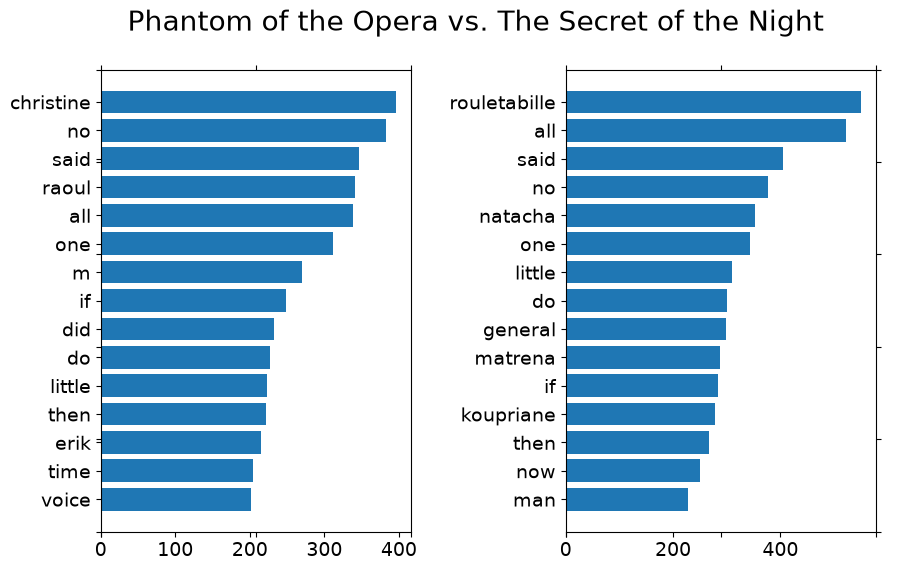

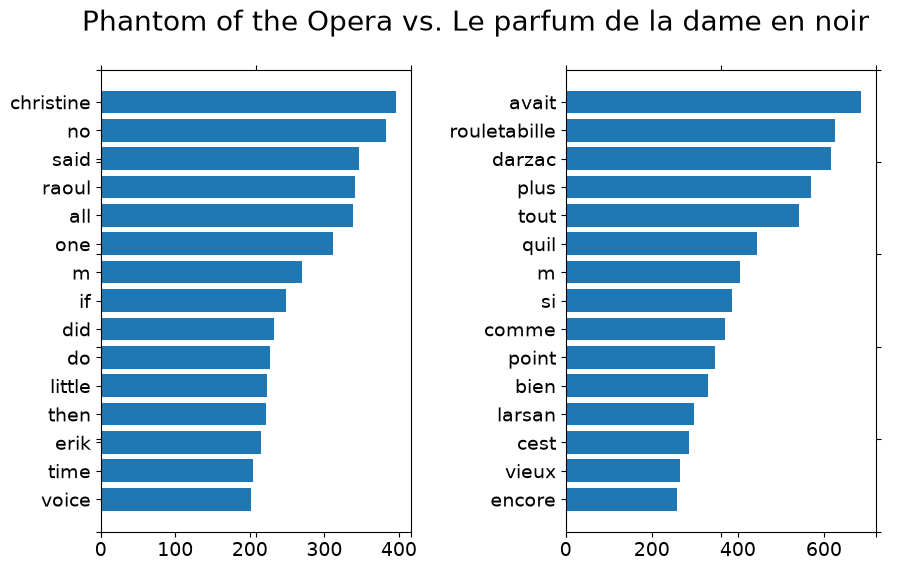

In [36]:
#Plot the results: are there striking differences in language?
import numpy as np
import pylab
import matplotlib.pyplot as plt


%matplotlib inline
def plotTwoLists (wf_ee, wf_bu, title):
    f = plt.figure (figsize=(10, 6))
    # this is painfully tedious....
    f .suptitle (title, fontsize=20)
    ax = f.add_subplot(111)
    ax .spines ['top'] .set_color ('none')
    ax .spines ['bottom'] .set_color ('none')
    ax .spines ['left'] .set_color ('none')
    ax .spines ['right'] .set_color ('none')
    ax .tick_params (labelcolor='w', top='off', bottom='off', left='off', right='off', labelsize=20)

    # Create two subplots, this is the first one
    ax1 = f .add_subplot (121)
    plt .subplots_adjust (wspace=.5)

    # MODIFIED the len(wf_ee) + 1
    pos = np .arange (len(wf_ee)) 
    ax1 .tick_params (axis='both', which='major', labelsize=14)
    pylab .yticks (pos, [ x [0] for x in wf_ee ])
    ax1 .barh (range(len(wf_ee)), [ x [1] for x in wf_ee ], align='center')

    ax2 = f .add_subplot (122)
    ax2 .tick_params (axis='both', which='major', labelsize=14)
     # MODIFIED the len(wf_bu) + 1
    pos = np .arange (len(wf_bu)) 
    pylab .yticks (pos, [ x [0] for x in wf_bu ])
    ax2 .barh (range (len(wf_bu)), [ x [1] for x in wf_bu ], align='center')

# get the top words in reverse order
book1_graph = book1_top_words[:15][::-1]
book2_graph = book2_top_words[:15][::-1]
book3_graph = book3_top_words[:15][::-1]


plotTwoLists(
    book1_graph,
    book2_graph,
    "Phantom of the Opera vs. The Secret of the Night"
)

plotTwoLists(
    book1_graph,
    book3_graph,
    "Phantom of the Opera vs. Le parfum de la dame en noir"
)

In [ ]:
'''

In summary, the author Gaston Leroux uses similar words in his two English novels Phantom of the Opera and The Secret of the Night. 
When translating his french most-used words into English, we get some crossover words such as "all" and "tout", as well as  "then" and 
"encore" but mainly, the words are different. There is much more similarity in his word choice between his two English novels.
'''